In [ ]:
!pip install mne -q

import os, glob, warnings
import numpy as np
import mne
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from scipy.signal import stft as scipy_stft
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')
torch.manual_seed(0); np.random.seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

In [3]:
FS = 250
MI_EVENT_CODES = {'769': 0, '770': 1, '771': 2, '772': 3}
CH_NAMES_2A = ['Fz',
               'FC3', 'FC1', 'FCz', 'FC2', 'FC4',
               'C5',  'C3',  'C1',  'Cz',  'C2',  'C4',  'C6',
               'CP3', 'CP1', 'CPz', 'CP2', 'CP4',
               'P1',  'Pz',  'P2',  'POz']
CLASS_NAMES = ['Left Hand', 'Right Hand', 'Feet', 'Tongue']

In [ ]:
# Preprocessing
def load_subject(file_path, tmin=0.0, tmax=3.0, l_freq=8., h_freq=30.):
    raw = mne.io.read_raw_gdf(file_path, preload=True, verbose=False)
    eog_chs = [c for c in raw.ch_names if 'EOG' in c.upper()]
    if eog_chs:
        raw.set_channel_types({c: 'eog' for c in eog_chs})
    raw.pick('eeg')
    if len(raw.ch_names) == len(CH_NAMES_2A):
        raw.rename_channels(dict(zip(raw.ch_names, CH_NAMES_2A)))
        raw.set_montage('standard_1020', match_case=False, on_missing='ignore')
    raw.filter(l_freq, h_freq, fir_design='firwin', verbose=False)
    events, event_id = mne.events_from_annotations(raw, verbose=False)
    mi_event_id = {c: event_id[c] for c in MI_EVENT_CODES if c in event_id}
    if not mi_event_id:
        return None, None, raw.ch_names
    epochs = mne.Epochs(raw, events, event_id=mi_event_id,
                        tmin=tmin, tmax=tmax,
                        baseline=None, preload=True,
                        reject_by_annotation=False, verbose=False)
    X = epochs.get_data()
    code_to_class = {event_id[c]: MI_EVENT_CODES[c] for c in mi_event_id}
    y = np.array([code_to_class[c] for c in epochs.events[:, 2]])
    return X.astype(np.float64), y.astype(np.int64), raw.ch_names

In [ ]:
# Load
drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/EEG_motor/Data/2a_gdf/'

files = sorted(glob.glob(DATA_DIR + '*.gdf'))
print(f'Found {len(files)} GDF file(s).')

all_X, all_y = [], []
for f in files:
    sid = os.path.splitext(os.path.basename(f))[0]
    X, y, ch_names = load_subject(f)
    if X is None:
        print(f'  {sid}: no MI events, skipping.')
        continue
    all_X.append(X)
    all_y.append(y)
    print(f'  {sid}: X={X.shape}')

X_all = np.concatenate(all_X, axis=0)
y_all = np.concatenate(all_y, axis=0)

print(f'\nRaw EEG shape: {X_all.shape}')
unique, counts = np.unique(y_all, return_counts=True)
for label, count in zip(unique, counts):
    print(f'  Label {label} ({CLASS_NAMES[label]}): {count} samples')

Mounted at /content/drive
Found 18 GDF file(s).
  A01E: no MI events, skipping.
  A01T: X=(288, 22, 751)
  A02E: no MI events, skipping.
  A02T: X=(288, 22, 751)
  A03E: no MI events, skipping.
  A03T: X=(288, 22, 751)
  A04E: no MI events, skipping.
  A04T: X=(288, 22, 751)
  A05E: no MI events, skipping.
  A05T: X=(288, 22, 751)
  A06E: no MI events, skipping.
  A06T: X=(288, 22, 751)
  A07E: no MI events, skipping.
  A07T: X=(288, 22, 751)
  A08E: no MI events, skipping.
  A08T: X=(288, 22, 751)
  A09E: no MI events, skipping.
  A09T: X=(288, 22, 751)

Raw EEG shape: (2592, 22, 751)
  Label 0 (Left Hand): 648 samples
  Label 1 (Right Hand): 648 samples
  Label 2 (Feet): 648 samples
  Label 3 (Tongue): 648 samples


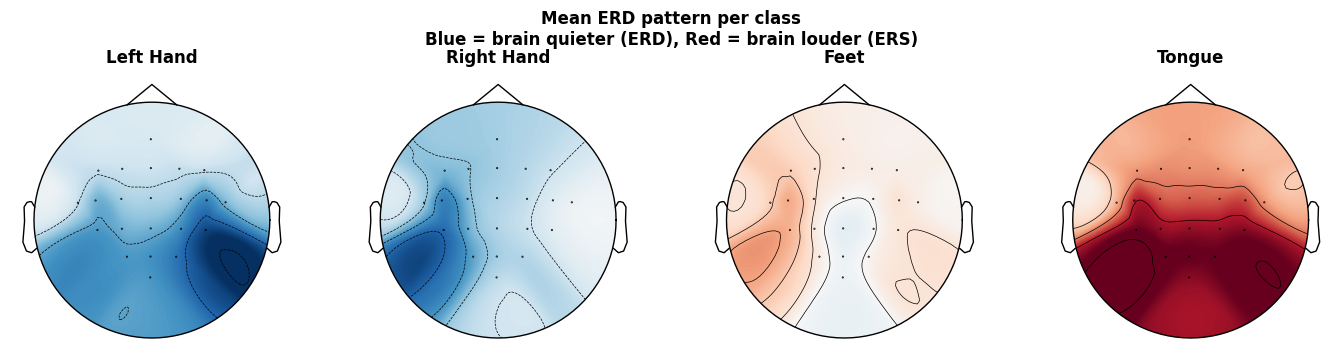

In [9]:
# Topographic maps
import mne
from matplotlib import pyplot as plt

def compute_relative_topo(X, y, n_classes=4):
    logbp = np.log(np.var(X, axis=-1) + 1e-12)
    class_topo = np.stack([logbp[y == c].mean(0) for c in range(n_classes)])
    return class_topo - class_topo.mean(0, keepdims=True)

# Pool all subjects
# Instead of subjects.values(), use X_all and y_all directly
X_pool = X_all.astype(np.float32)  # (trials, 22, 751) — raw EEG before STFT
y_pool = y_all.astype(np.int64)
topo   = compute_relative_topo(X_pool, y_pool)

info = mne.create_info(CH_NAMES_2A, FS, ch_types='eeg')
info.set_montage('standard_1020', match_case=False, on_missing='ignore')

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
vmax = np.percentile(np.abs(topo), 98)
for c in range(4):
    mne.viz.plot_topomap(topo[c], info, axes=axes[c], show=False,
                         vlim=(-vmax, vmax), cmap='RdBu_r', contours=4)
    axes[c].set_title(CLASS_NAMES[c], fontweight='bold')

fig.suptitle('Mean ERD pattern per class\nBlue = brain quieter (ERD), Red = brain louder (ERS)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('topomaps.png', dpi=150)
plt.show()

In [13]:
#STFT
def compute_stft(X, fs=250, win_sec=0.5, overlap=0.5):
    nperseg  = int(fs * win_sec)
    noverlap = int(nperseg * overlap)
    f, t, Z  = scipy_stft(X, fs=fs, nperseg=nperseg, noverlap=noverlap, axis=-1)
    S = np.log(np.abs(Z) + 1e-8).astype(np.float32)
    return S, f, t

X_stft, freqs, times = compute_stft(X_all.astype(np.float32))
y_clean = y_all.astype(np.int64)

print(f'STFT shape: {X_stft.shape}')  # (trials, 22, n_freqs, n_times)
print(f'Freq bins: {len(freqs)} | Time bins: {len(times)}')

STFT shape: (2592, 22, 63, 13)
Freq bins: 63 | Time bins: 13


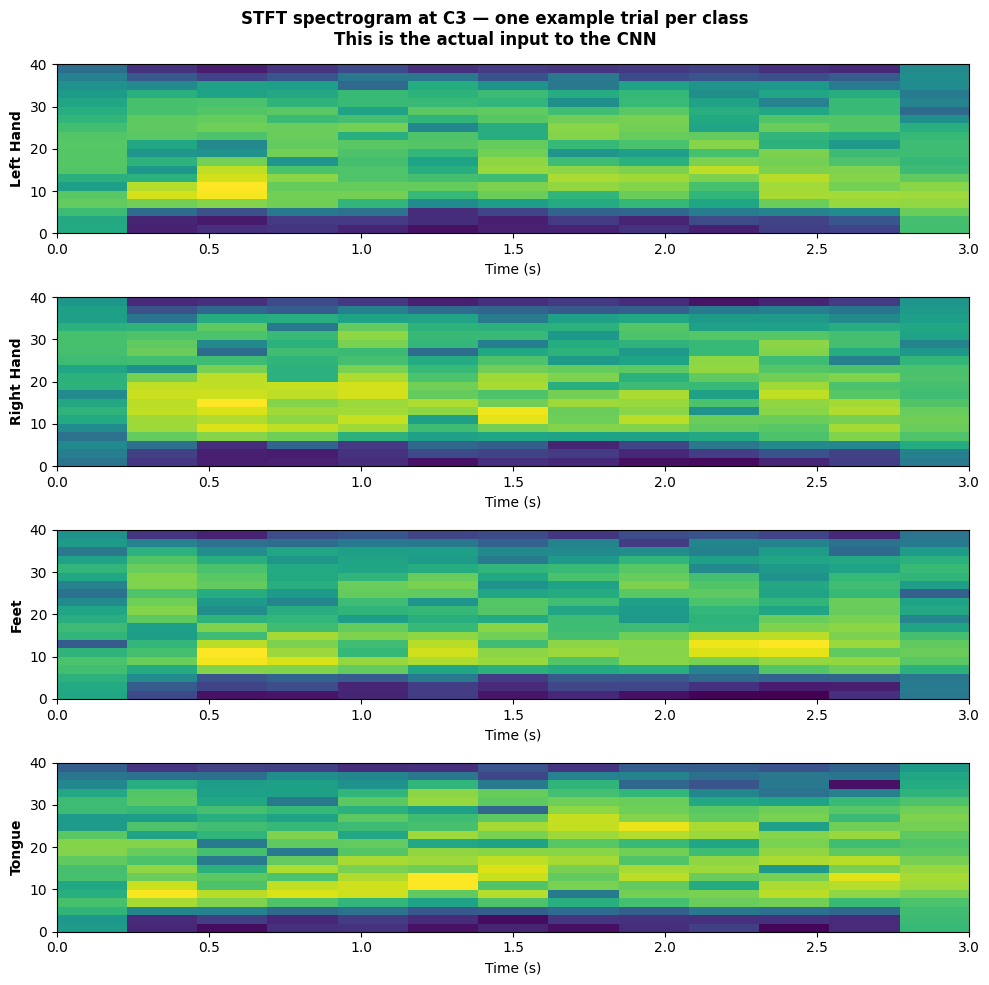

In [23]:
# Representation of STFT spectogram
fig, axes = plt.subplots(4, 1, figsize=(10, 10))
c3_idx = CH_NAMES_2A.index('C3')

for c in range(4):
    trial_idx = np.where(y_clean == c)[0][0]
    spec = X_stft[trial_idx, c3_idx, :, :]  # C3 channel spectrogram

    axes[c].imshow(spec, aspect='auto', origin='lower',
                   cmap='viridis',
                   extent=[0, 3, 0, FS//2])
    axes[c].set_ylabel(CLASS_NAMES[c], fontweight='bold')
    axes[c].set_xlabel('Time (s)')
    axes[c].set_ylim(0, 40)  # show up to 40 Hz

fig.suptitle('STFT spectrogram at C3 — one example trial per class\n'
             'This is the actual input to the CNN', fontweight='bold')
plt.tight_layout()
plt.savefig('stft_examples.png', dpi=150)
plt.show()

In [ ]:
# Split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_stft, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

# Normalise using training stats only
mu = X_train.mean(axis=(0, 2, 3), keepdims=True)
sd = X_train.std(axis=(0, 2, 3), keepdims=True) + 1e-6
X_train = (X_train - mu) / sd
X_val   = (X_val   - mu) / sd
X_test  = (X_test  - mu) / sd

print(f'Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}')

def to_tensor(X, y):
    return TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

BATCH_SIZE = 32
train_loader = DataLoader(to_tensor(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(to_tensor(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(to_tensor(X_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

Train: 1554 | Val: 519 | Test: 519


In [ ]:
# Model
class EEG_CNN(nn.Module):
    def __init__(self, n_channels, n_freqs, n_times, n_classes=4, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1 — double conv
            nn.Conv2d(n_channels, 64, kernel_size=3, padding=1),  # 64 not 32
            nn.BatchNorm2d(64), nn.ELU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),           # second conv
            nn.BatchNorm2d(64), nn.ELU(),
            nn.MaxPool2d(2), nn.Dropout2d(dropout),

            # Block 2 — double conv
            nn.Conv2d(64, 128, kernel_size=3, padding=1),          # 128 not 64
            nn.BatchNorm2d(128), nn.ELU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),         # second conv
            nn.BatchNorm2d(128), nn.ELU(),
            nn.AdaptiveAvgPool2d((4, 4)), nn.Dropout2d(dropout),   # (4,4) not (4,2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ELU(),  # 128*16=2048 not 64*8=512
            nn.Dropout(dropout),
            nn.Linear(256, 64), nn.ELU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = EEG_CNN(
    n_channels=X_stft.shape[1],
    n_freqs=X_stft.shape[2],
    n_times=X_stft.shape[3],
    n_classes=4,
    dropout=0.5
).to(device)

optimizer = optim.Adam(model.parameters(), lr=5e-4, weight_decay=5e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=8, factor=0.5)
criterion = nn.CrossEntropyLoss()
print(model)

EEG_CNN(
  (features): Sequential(
    (0): Conv2d(22, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ELU(alpha=1.0)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.5, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ELU(alpha=1.0)
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ELU(alpha=1.0)
    (14): AdaptiveAvgPool2d(output_size=(4, 4))
    (15): Dropout2d(p=0.5, inpl

In [16]:
class_counts = np.bincount(y_train)
class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum()
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f'Class weights: {class_weights}')

# criterion = nn.CrossEntropyLoss(weight=class_weights)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5)
NUM_EPOCHS = 100

Class weights: tensor([0.2497, 0.2497, 0.2503, 0.2503], device='cuda:0')


In [ ]:
# Train
train_losses, val_losses = [], []
train_accs,   val_accs   = [], []
best_val_loss = float('inf')

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        correct += (outputs.argmax(1) == y_batch).sum().item()
        total   += y_batch.size(0)

    train_loss = running_loss / len(train_loader)
    train_acc  = correct / total

    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            val_loss_sum += criterion(outputs, y_batch).item()
            val_correct  += (outputs.argmax(1) == y_batch).sum().item()
            val_total    += y_batch.size(0)

    val_loss = val_loss_sum / len(val_loader)
    val_acc  = val_correct / val_total
    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), '/content/drive/MyDrive/EEG_motor/best_eeg_cnn.pt')

    train_losses.append(train_loss); val_losses.append(val_loss)
    train_accs.append(train_acc);    val_accs.append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1:03d}/{NUM_EPOCHS}]  '
              f'Train Loss: {train_loss:.4f}  Acc: {train_acc:.3f}  |  '
              f'Val Loss: {val_loss:.4f}  Acc: {val_acc:.3f}')

print('\nTraining complete.')

Epoch [010/100]  Train Loss: 1.4228  Acc: 0.250  |  Val Loss: 1.3871  Acc: 0.274
Epoch [020/100]  Train Loss: 1.4025  Acc: 0.250  |  Val Loss: 1.3847  Acc: 0.287
Epoch [030/100]  Train Loss: 1.3871  Acc: 0.279  |  Val Loss: 1.3833  Acc: 0.295
Epoch [040/100]  Train Loss: 1.3827  Acc: 0.302  |  Val Loss: 1.3812  Acc: 0.304
Epoch [050/100]  Train Loss: 1.3685  Acc: 0.299  |  Val Loss: 1.3783  Acc: 0.291
Epoch [060/100]  Train Loss: 1.3509  Acc: 0.325  |  Val Loss: 1.3780  Acc: 0.339
Epoch [070/100]  Train Loss: 1.3415  Acc: 0.339  |  Val Loss: 1.3785  Acc: 0.316
Epoch [080/100]  Train Loss: 1.3451  Acc: 0.337  |  Val Loss: 1.3767  Acc: 0.322
Epoch [090/100]  Train Loss: 1.3387  Acc: 0.342  |  Val Loss: 1.3770  Acc: 0.310
Epoch [100/100]  Train Loss: 1.3392  Acc: 0.340  |  Val Loss: 1.3770  Acc: 0.304

Training complete.


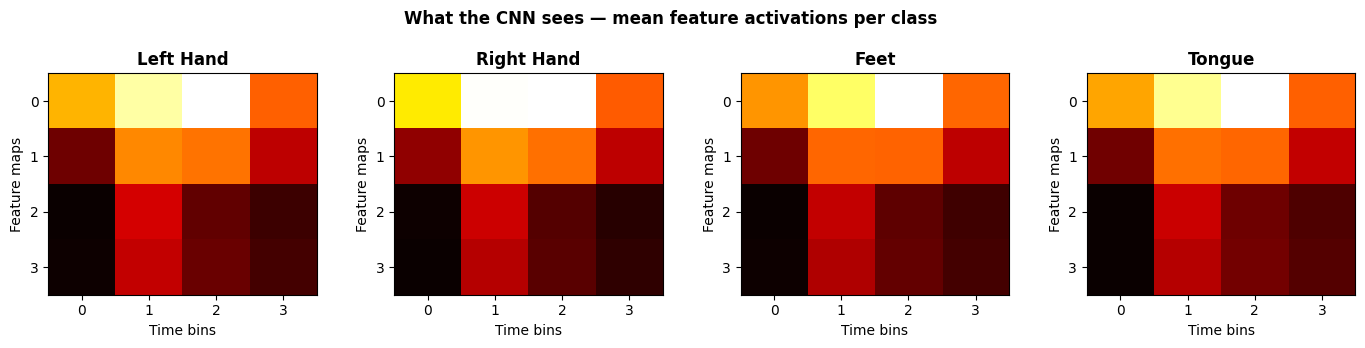

In [ ]:
# Evaluate
model.eval()
activation_maps = {c: [] for c in range(4)}

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        features = model.features(X_batch)  # get conv output before classifier
        for i, label in enumerate(y_batch):
            activation_maps[label.item()].append(features[i].cpu().mean(0).numpy())

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for c in range(4):
    mean_map = np.mean(activation_maps[c], axis=0)
    axes[c].imshow(mean_map, aspect='auto', cmap='hot')
    axes[c].set_title(CLASS_NAMES[c], fontweight='bold')
    axes[c].set_xlabel('Time bins')
    axes[c].set_ylabel('Feature maps')

fig.suptitle('What the CNN sees — mean feature activations per class', fontweight='bold')
plt.tight_layout()
plt.savefig('cnn_activations.png', dpi=150)

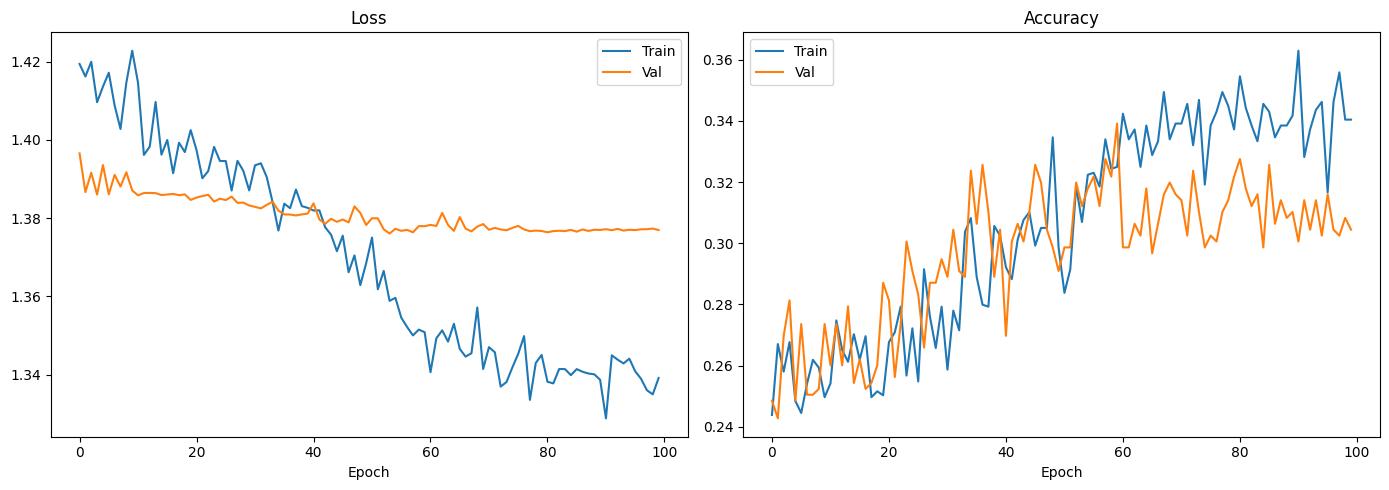

In [ ]:
# Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses, label='Train'); axes[0].plot(val_losses, label='Val')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(train_accs,  label='Train'); axes[1].plot(val_accs,  label='Val')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig('training_curves.png', dpi=150); plt.show()

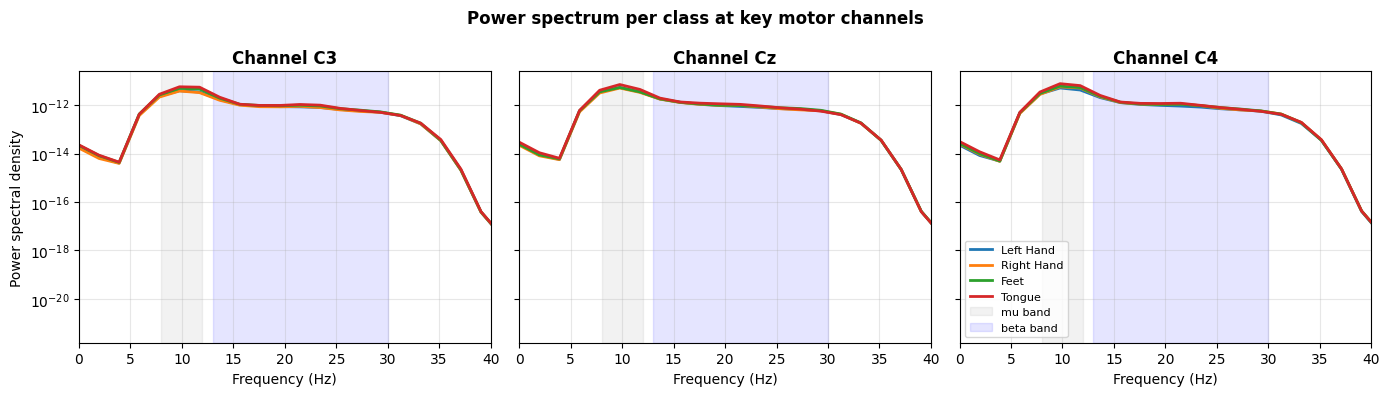

In [20]:
from scipy.signal import welch

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
key_channels = ['C3', 'Cz', 'C4']
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

for ax, ch_name in zip(axes, key_channels):
    ch_idx = CH_NAMES_2A.index(ch_name)
    for c in range(4):
        trials = X_pool[y_pool == c, ch_idx, :]
        freqs_w, psd = welch(trials, fs=FS, nperseg=128, axis=-1)
        mean_psd = psd.mean(0)
        ax.semilogy(freqs_w, mean_psd, label=CLASS_NAMES[c],
                    color=colors[c], linewidth=2)
    ax.axvspan(8, 12, alpha=0.1, color='gray', label='mu band')
    ax.axvspan(13, 30, alpha=0.1, color='blue', label='beta band')
    ax.set_xlim(0, 40)
    ax.set_title(f'Channel {ch_name}', fontweight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Power spectral density')
axes[2].legend(fontsize=8)
fig.suptitle('Power spectrum per class at key motor channels',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('psd_per_class.png', dpi=150)
plt.show()

              precision    recall  f1-score   support

   Left Hand       0.30      0.32      0.31       130
  Right Hand       0.33      0.55      0.42       129
        Feet       0.31      0.18      0.23       130
      Tongue       0.31      0.22      0.25       130

    accuracy                           0.32       519
   macro avg       0.31      0.32      0.30       519
weighted avg       0.31      0.32      0.30       519



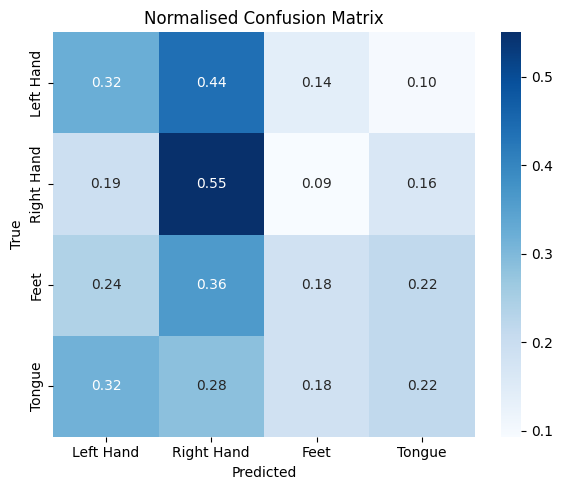

In [ ]:
# Evaluate on test set
model.load_state_dict(torch.load('/content/drive/MyDrive/EEG_motor/best_eeg_cnn.pt', map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        preds = model(X_batch.to(device)).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

cm = confusion_matrix(all_labels, all_preds, normalize='true')
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Normalised Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

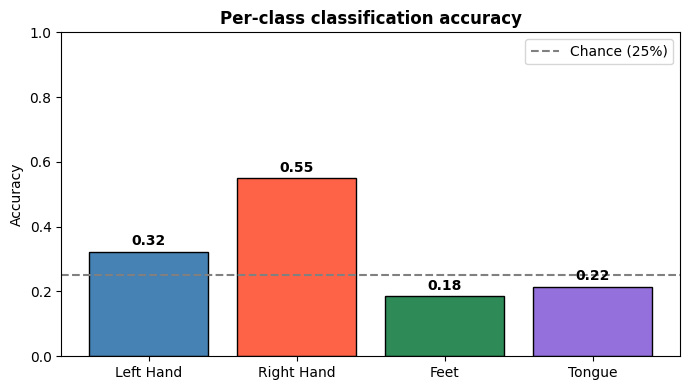

In [22]:
# Per class accuracy chart
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(all_labels, all_preds)
per_class_acc = cm.diagonal() / cm.sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_NAMES, per_class_acc,
              color=['steelblue', 'tomato', 'seagreen', 'mediumpurple'],
              edgecolor='black')
ax.axhline(0.25, color='gray', linestyle='--', label='Chance (25%)')
ax.set_ylim(0, 1)
ax.set_ylabel('Accuracy')
ax.set_title('Per-class classification accuracy', fontweight='bold')
ax.legend()

for bar, acc in zip(bars, per_class_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{acc:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('per_class_accuracy.png', dpi=150)
plt.show()